In [1]:
"""This file is to test dedicated algorithms
"""

import config as cfg
from data_acquirer import get_data, gen_data
from data_processor import process
import helpers
import heuristic
from heuristic import Path, VGeneralizedSolver
from solver import solve_pdpcr


import pickle
import copy
import datetime
from docplex.mp.model import Model
import logging
import heapq
import networkx as nx
import numpy as np
import random 
import time

logging.basicConfig(format=cfg.LOG_FORMATTER, level=cfg.LOG_LEVEL, datefmt='%d-%b-%y %H:%M:%S')

In [2]:
# Test dedicated insert functions

# Data from document "redistribute paper"
sol_graph = nx.DiGraph()
sol_graph.add_edge(0, 1, weight=5)
sol_graph.add_edge(0, 2, weight=2)
sol_graph.add_edge(1, 3, weight=1)
# sol_graph.add_edge(1, 4, weight=4)
sol_graph.add_edge(1, -1, weight=4)
sol_graph.add_edge(2, 3, weight=1)
sol_graph.add_edge(2, 5, weight=1)
sol_graph.add_edge(3, 5, weight=2)
# sol_graph.add_edge(4, -1, weight=4)
sol_graph.add_edge(5, -1, weight=3)

N_left = [0,1,2,3]
N_right = [5,-1]
l = {
    0:0,
    1:4,
    2:7,
    3:12,
    # 4:11,
    5:20,
    -1:24
}

l_bar ={
    0:0,
    1:9,
    2:9,
    3:16,
    # 4:14,
    5:22,
    -1:24
}

l_star = {
    0:24,
    1:18,
    2:17,
    3:12,
    # 4:5,
    5:4,
    -1:0
}

ls = (l,l_bar,l_star, None)

c_travel = {
    0:{
        1:4,
        2:7,
        4:66,
        5:88,
        -1:0
    },
    1:{
        4:6,
        5:4,
        -1:99
    },
    2:{
        4:2,
        5:3,
        -1:99
    },
    3:{
        4:1,
        5:4,
        -1:99
    },
    4:{
        4:99,
        -1:2,
        5:9
    },
}

c_operate = {
    0:0,
    1:1,
    2:2,
    3:4,
    4:3,
    5:1,
    -1:0
}

pi_left={
    0:0,
    1:4,
    2:1,
    3:2
}

pi_right = {
    # 4:4,
    5:3,
    -1:3
}

greedy = heuristic.GreedyInsert(None,c_travel,c_operate)

In [3]:
i_hat = 4
n_i_hat = 4
sol_graph, C_max = greedy._high_dedicated_insert(sol_graph, N_left, N_right,  pi_left, pi_right,ls,i_hat,n_i_hat)
print(C_max)

12-Nov-24 19:26:06:INFO:Current thetas: [14, 18, 20]
12-Nov-24 19:26:06:INFO:Current thetas: [14, 18]


22


In [12]:
sol_graph.edges(data=True)

OutEdgeDataView([(0, 1, {'weight': 5}), (0, 2, {'weight': 2}), (1, 3, {'weight': 1}), (1, 5, {'weight': 2}), (1, 4, {'weight': 2}), (2, 3, {'weight': 1}), (2, 5, {'weight': 1}), (3, 4, {'weight': 2}), (5, -1, {'weight': 3}), (4, -1, {'weight': 4})])

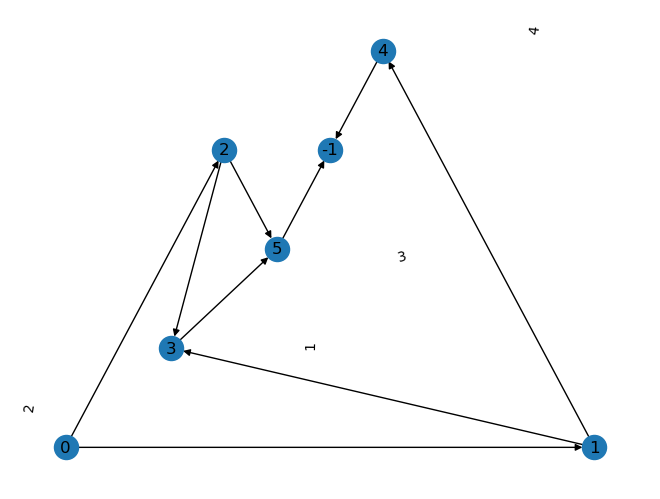

In [7]:
#Draw the graph
import matplotlib.pyplot as plt
pos = nx.spring_layout(sol_graph)
nx.draw_planar(sol_graph, with_labels=True)
labels = nx.get_edge_attributes(sol_graph, 'weight')
nx.draw_networkx_edge_labels(sol_graph, pos, edge_labels=labels)
plt.show()

In [9]:
topo_order  = list(nx.topological_sort(sol_graph))
greedy._get_related_times(sol_graph, greedy.c_travel, greedy.c_operate, topo_order)

KeyError: 0

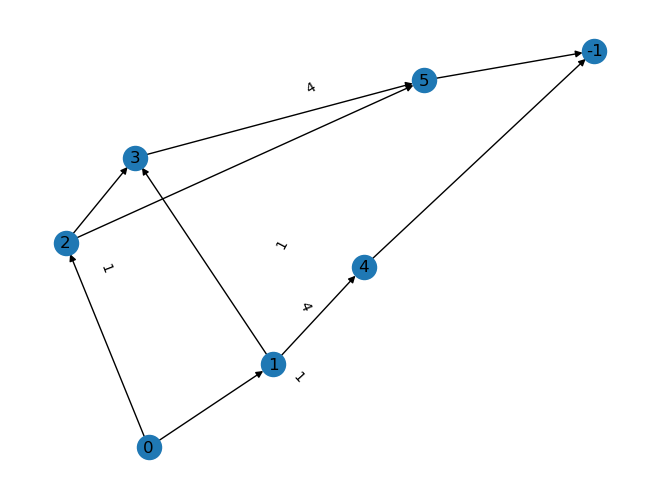

In [ ]:
#Draw the graph as a DAG
import matplotlib.pyplot as plt
pos = nx.spring_layout(sol_graph)
nx.draw(sol_graph, with_labels=True)
labels = nx.get_edge_attributes(sol_graph, 'weight')
nx.draw_networkx_edge_labels(sol_graph, pos, edge_labels=labels)
plt.show()


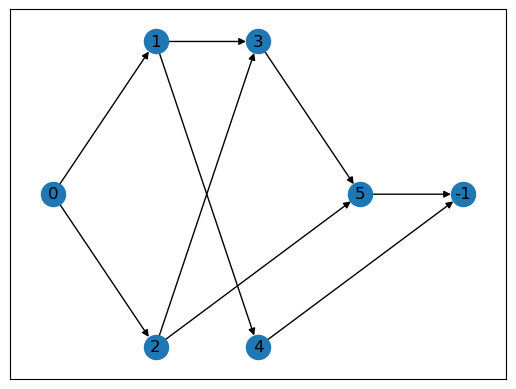

In [21]:
for layer, nodes in enumerate(nx.topological_generations(sol_graph)):
    # `multipartite_layout` expects the layer as a node attribute, so add the
    # numeric layer value as a node attribute
    for node in nodes:
        sol_graph.nodes[node]["layer"] = layer
pos = nx.multipartite_layout(sol_graph, subset_key="layer")
nx.draw_networkx(sol_graph, pos, with_labels=True)

In [ ]:
# Test tabu dedicated redistribute functions

# Data from document "redistribute paper"
sol_graph = nx.DiGraph()
sol_graph.add_edge(0, 1, weight=5)
sol_graph.add_edge(0, 2, weight=2)
sol_graph.add_edge(1, 3, weight=1)
sol_graph.add_edge(1, 4, weight=4)
sol_graph.add_edge(2, 3, weight=1)
sol_graph.add_edge(2, 5, weight=1)
sol_graph.add_edge(3, 5, weight=2)
sol_graph.add_edge(4, -1, weight=4)
sol_graph.add_edge(5, -1, weight=3)

N_left = [0,1,2,3]
N_right = [4,5,-1]
l = {
    0:0,
    1:4,
    2:7,
    3:12,
    4:11,
    5:20,
    -1:24
}

l_bar ={
    0:0,
    1:9,
    2:9,
    3:16,
    4:14,
    5:22,
    -1:24
}

l_star = {
    0:24,
    1:18,
    2:17,
    3:12,
    4:5,
    5:4,
    -1:0
}

ls = (l,l_bar,l_star)

c_travel = {
    0:{
        1:4,
        2:7,
        4:66,
        5:88,
        -1:0
    },
    1:{
        4:6,
        5:4,
        -1:99
    },
    2:{
        4:2,
        5:3,
        -1:99
    },
    3:{
        4:1,
        5:4,
        -1:99
    }
}

c_operate = {
    0:0,
    1:1,
    2:2,
    3:4,
    4:3,
    5:1,
    -1:0
}

pi_left={
    0:0,
    1:4,
    2:1,
    3:2
}

pi_right = {
    4:4,
    5:3,
    -1:0
}

tabu = heuristic.TabuSearch(None,c_travel,c_operate)

In [ ]:
tabu._dedicated_redistribute(sol_graph, N_left, N_right,pi_left, pi_right, ls)

In [2]:

total_robots = 2
random_data = False

data_type = 'csv'
data_name = 'data2.csv'
# data_name = 'data3.csv'
# data_name = 'lim/100/lrc203-5-uniform.csv'
# data_name = 'lim/200/LC1_2_3-5-uniform.csv'
total_tasks = 6 # random data

raw = get_data(data_name, data_type)
logging.info(f'Solving data {data_name} with {total_robots} robots and {len(raw.tasks)} tasks')
processed_h = heuristic.process_greedy_1(raw)

depot = processed_h.depot
tasks = processed_h.tasks
c_travel = helpers.create_task_dist_dict(depot,tasks)
c_operate = helpers.create_operate_dict(depot,tasks)

12-Nov-24 19:30:45:INFO:Solving data data2.csv with 2 robots and 3 tasks


In [6]:
cfg.DEDICATED_INSERT = True
greedy_v2 = heuristic.GreedyInsert(processed_h, c_travel, c_operate)
greddy_v2_F, greedy_v2_C_max = greedy_v2.solve(total_robots)
print(f'greedy insert makespan: {greedy_v2_C_max}')

greedy insert makespan: 1744.193613341567


In [29]:
greddy_v2_F.edges(data=True)

OutEdgeDataView([(0, 3, {'weight': 1}), (0, 2, {'weight': 1}), (3, 1, {'weight': 1}), (2, 1, {'weight': 1}), (1, -1, {'weight': 1})])

In [8]:
greddy_v2_F.edges(data=True)

OutEdgeDataView([(0, 1, {'weight': 1}), (0, 3, {'weight': 1}), (1, -1, {'weight': 1}), (3, 2, {'weight': 1}), (2, 1, {'weight': 1})])

In [6]:
#Li larger data

first_names = ['LC1']
sec_names = [2,4,6,8,10]
third_names = [i for i in range(1,11)]
data_paths =[f'lim/{j}00/{i}_{j}_{k}-5-uniform.csv'for i in first_names for j in sec_names for k in third_names]#
num_robots = [10*i for i in range(1,4)]
method = 5
file_type = 'csv'
is_depot_task = False

In [7]:
#Li smaller data
small_first_names =['lc','lr','lrc']
small_sec_names = [100+i for i in range(1,10)] + [200 + i for i in range(1,10)]
data_paths = [f'lim/100/{i}{j}-5-uniform.csv' for i in small_first_names for j in small_sec_names]


In [8]:
data_paths = [data_paths[0]]
num_robots = [10]
file_type = 'csv'
is_depot_task = False
solve_note = 'dedicated insert'
#new greedy search
for num_robot in num_robots:
    for data_path in data_paths:
        try:
            raw = get_data(data_path, file_type, is_depot_task)
            logging.info(f'Solving data {data_path} with {num_robot} robots and {len(raw.tasks)} tasks')
            # processed_data = process(raw, method)
            processed_h = heuristic.process_greedy_1(raw)
            depot = processed_h.depot
            tasks = processed_h.tasks
            c_travel = helpers.create_task_dist_dict(depot,tasks)
            c_operate = helpers.create_operate_dict(depot,tasks)

            tik1 = time.time()
            greedy_v2 = heuristic.GreedyInsert(processed_h, c_travel, c_operate)
            greedy_v2_F, greedy_v2_C_max = greedy_v2.solve(num_robot)
            tok1 = time.time()
            greedy_time = tok1 - tik1
            if cfg.TABU_SAVE_FITNESSES:
                data_name = data_path.split('/')[2].split('.')[0]
                #add current time to data_name
                data_name += '_'+ datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
                pickle.dump(greedy_v2_F, open(f'solve_results/greedy2/{data_name}.p', 'wb'))
        
            solve_log = []
            solve_log.append(data_path)
            solve_log.append(num_robot)
            solve_log.append(greedy_v2_C_max)
            solve_log.append(np.round(greedy_time,2))
            now = datetime.datetime.now()
            solve_log.append(now)
            solve_log.append(solve_note)
            with open('solve_log_greedy2.csv', 'a') as f:
                f.write(','.join([str(i) for i in solve_log])+'\n')
        except Exception as e:
            print(f'\n ______________Error in {data_path} with {num_robot} robots______________\n')
            print(e)
            raise(e)

12-Nov-24 11:43:16:INFO:Solving data lim/100/lc101-5-uniform.csv with 10 robots and 53 tasks
12-Nov-24 11:43:16:INFO:zeta: 1
12-Nov-24 11:43:16:INFO:C_max dedicated after insert task 42: 0
12-Nov-24 11:43:16:INFO:zeta: 1
12-Nov-24 11:43:16:INFO:C_max dedicated after insert task 48: 107.94652186142355
12-Nov-24 11:43:16:INFO:zeta: 2
12-Nov-24 11:43:16:INFO:Current thetas: [27.685528128088304]
12-Nov-24 11:43:16:INFO:C_max dedicated after insert task 48: 107.94652186142355
12-Nov-24 11:43:16:INFO:zeta: 1
12-Nov-24 11:43:16:INFO:C_max dedicated after insert task 6: 121.75582930849986
12-Nov-24 11:43:16:INFO:zeta: 2
12-Nov-24 11:43:16:INFO:Current thetas: [29.6968827043885]
12-Nov-24 11:43:16:INFO:C_max dedicated after insert task 6: 107.94652186142355
12-Nov-24 11:43:16:INFO:zeta: 3
12-Nov-24 11:43:16:INFO:Current thetas: [29.6968827043885, 69.05644765481995]
12-Nov-24 11:43:16:INFO:Current thetas: [29.6968827043885]
12-Nov-24 11:43:16:INFO:C_max dedicated after insert task 6: 121.7558293

In [ ]:
first_names = ['LC1']
sec_names = [2,4,6]
third_names = [i for i in range(1,11)]
data_paths =[f'lim/{j}00/{i}_{j}_{k}-5-uniform.csv'for i in first_names for j in sec_names for k in third_names]#
num_robots = [10*i for i in range(1,4)]
method = 5
file_type = 'csv'
is_depot_task = False

In [ ]:
num_robots = [10]
file_type = 'csv'
is_depot_task = False

for num_robot in num_robots:
    for data_path in data_paths:
        try:
            raw = get_data(data_path, file_type, is_depot_task)
            logging.info(f'Solving data {data_path} with {num_robot} robots and {len(raw.tasks)} tasks')
            # processed_data = process(raw, method)
            processed_h = heuristic.process_greedy_1(raw)
            depot = processed_h.depot
            tasks = processed_h.tasks
            c_travel = helpers.create_task_dist_dict(depot,tasks)
            c_operate = helpers.create_operate_dict(depot,tasks)

            cur_best_makespan = np.infty
            for i in range(30):
                solve_viet = VGeneralizedSolver(processed_h, c_travel, c_operate)
                cur_sol = solve_viet.solve(num_robot,'random',cfg.TABU_INIT_CONSIDER_PROCESS_TIME,task_range=[1,4])
                makespan = cur_sol.get_makespan()
    
                if makespan < cur_best_makespan:
                    init_sol  = cur_sol
                    cur_best_makespan = makespan
            
            #save init_sol as file knowing that init_sol is an instance of Solution class
            data_name = data_path.split('/')[2].split('.')[0]
            pickle.dump(init_sol, open(f'solve_results/init_data/{data_name}.p', 'wb'))

        except Exception as e:
            print(f'\n ______________Error in {data_path} with {num_robot} robots______________\n')
            print(e)
            raise(e)